# Predicting Eruptive Events at Kilauea from Earthquake Data
**Replication + extension of** *Mullet, Singh & Wong (Stanford CS229, Fall 2019)* — data from the authors' repo [`bmullet/PEEVED`](https://github.com/bmullet/PEEVED).

**Runtime:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`. Expected total: **~10–25 min** (the 1000-epoch neural nets are the slow part; everything else is seconds to a couple of minutes).

| | Part A — Replication | Part B — Our twist |
|---|---|---|
| Split | authors' random 70/20/10 index files | **blocked-in-time** split (14-day blocks) — no leakage between neighbouring quakes |
| Scaling | fit on all data (as in paper) | **fit on train only** |
| Features | lon, lat, depth, mag, quake counts (1d / 7d / 30d) | + log seismic energy 7d, max magnitude 7d, mean depth 7d, day/month rate ratio, log time since previous quake |
| Imbalance (~80% repose) | none | class-weighted LR / RF / HistGB, **weighted BCE** NN, dev-tuned decision threshold |
| Models | LR, k-means, RF, NN (4×1000) | same + HistGradientBoosting |

Two tasks: **(1) classification** — is the volcano erupting at the time of this quake? **(2) regression** — scaled time until the next eruption (0 if already erupting).

## 0. Setup

In [1]:
import os, subprocess, time, warnings
warnings.filterwarnings('ignore')

# Get the authors' data (all CSVs are in the repo)
if os.path.basename(os.getcwd()) != 'PEEVED':
    if not os.path.exists('PEEVED'):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/bmullet/PEEVED.git'], check=True)
    os.chdir('PEEVED')
print('working dir:', os.getcwd())

working dir: /content/PEEVED


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn import metrics
import torch, torch.nn as nn

SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
if device.type == 'cpu':
    print('WARNING: no GPU found. Runtime > Change runtime type > T4 GPU (CPU works but the NNs take ~20 min each).')

# ---------------- knobs ----------------
RUN_NN     = True     # set False to skip the neural nets (everything else runs in ~2 min)
NN_EPOCHS  = 1000
NN_BATCH   = 50       # as in the paper
NN_HIDDEN  = 1000     # 4 hidden layers x 1000 units (~3M params), as in the paper
NN_CLS = dict(lr=0.01, wd=1e-3)   # SGD learning rate / weight decay, classification
NN_REG = dict(lr=0.01, wd=1e-4)   # SGD learning rate / weight decay, regression
BLOCK_DAYS = 14       # block length for the Part B split

device: cuda


## 1. Data, labels and features
* Earthquakes (ANSS catalogue via WOVOdat) are cropped to the **East Rift Zone** with the same line the authors used → should give **3764** quakes.
* *Erupting* label: quake happens within (episode length + 24 h) after an eruption start listed in `PuuOo.csv`.
* *Time to eruption* (seconds): 0 if erupting, else time to the next listed eruption start.
* Quake-rate features use binary search on the sorted catalogue (the authors' O(n²) Python loops are replaced by an equivalent vectorised version).

In [3]:
eq = pd.read_csv('puuoo_earthquakes.csv')
eq['time'] = pd.to_datetime(eq['Date-time'], format='%m/%d/%Y %H:%M:%S')
eq = eq.rename(columns={'Latitude':'lat','Longitude':'lon','Depth':'depth','Magnitude':'mag'})[['time','lat','lon','depth','mag']]

# East Rift Zone crop: keep points on/below the line through (-155.5,19.3) and (-155.0,19.5)
slope = (19.5 - 19.3) / (-155.0 + 155.5)
intercept = 19.3 - slope * (-155.5)
eq = eq[(eq.lat - slope*eq.lon - intercept) <= 0].sort_values('time', kind='stable').reset_index(drop=True)
print('East Rift Zone quakes:', len(eq), '(paper: 3764)')
print('catalogue span:', eq.time.min().date(), '->', eq.time.max().date())

er = pd.read_csv('PuuOo.csv')
er['date']  = pd.to_datetime(er['Date'], format='%m/%d/%y')
er['len_h'] = er['Length'].str.replace(' hrs', '', regex=False).astype(float)
print('eruption episodes:', len(er))

East Rift Zone quakes: 3764 (paper: 3764)
catalogue span: 1983-01-01 -> 1986-12-30
eruption episodes: 49


In [4]:
t      = eq.time.values.astype('datetime64[s]')
edates = er.date.values.astype('datetime64[s]')
elen   = er.len_h.values
nE     = len(edates)

# --- labels ---
prev = np.searchsorted(edates, t, side='left') - 1            # last eruption start strictly before the quake
pc   = np.maximum(prev, 0)
hrs_since = (t - edates[pc]).astype('timedelta64[s]').astype(float) / 3600
erupting  = (prev >= 0) & (hrs_since < elen[pc] + 24)         # 24 h buffer, as in the authors' code

nxt = np.searchsorted(edates, t, side='right')                # first eruption start strictly after the quake
nc  = np.minimum(nxt, nE - 1)
secs_to = np.where(erupting, 0.0,
          np.where(nxt < nE, (edates[nc] - t).astype('timedelta64[s]').astype(float), np.nan))
assert not np.isnan(secs_to).any()

y_cls = erupting.astype(int)
y_tte = secs_to
print('fraction erupting: %.3f   (paper: ~20%% positive)' % y_cls.mean())

# --- quake-rate features (strictly earlier quakes inside the window) ---
ts = (t - t[0]).astype('timedelta64[s]').astype(float)
def window(days):
    hi = np.searchsorted(ts, ts, side='left')
    lo = np.searchsorted(ts, ts - days*86400, side='left')
    return lo, hi

feat = pd.DataFrame({'lon': eq.lon, 'lat': eq.lat, 'depth': eq.depth, 'mag': eq.mag})
for name, d in [('eq_day', 1), ('eq_week', 7), ('eq_month', 30)]:
    lo, hi = window(d); feat[name] = hi - lo
BASE_COLS = list(feat.columns)

# --- extra features (Part B) ---
energy = 10 ** (1.5 * eq.mag.values + 4.8)                    # radiated seismic energy (J), Gutenberg-Richter
cs_e = np.concatenate([[0], np.cumsum(energy)])
cs_d = np.concatenate([[0], np.cumsum(eq.depth.values)])
lo7, hi7 = window(7)
feat['log_energy_7d'] = np.log10(1 + (cs_e[hi7] - cs_e[lo7]))
n7 = hi7 - lo7
feat['meandepth_7d'] = np.where(n7 > 0, (cs_d[hi7] - cs_d[lo7]) / np.maximum(n7, 1), eq.depth.mean())
mag = eq.mag.values
feat['maxmag_7d'] = [mag[l:h].max() if h > l else mag.min() for l, h in zip(lo7, hi7)]
feat['rate_ratio_d_m'] = (feat.eq_day + 1) / (feat.eq_month + 1)
gap_h = np.r_[np.nan, np.diff(ts)] / 3600
feat['log_gap_prev'] = np.log10(1 + np.nan_to_num(gap_h, nan=np.nanmedian(gap_h)))
EXT_COLS = list(feat.columns)

print(feat.describe().T[['mean', 'std', 'min', 'max']].round(2))

fraction erupting: 0.217   (paper: ~20% positive)
                  mean    std     min     max
lon            -155.18   0.10 -155.52 -155.00
lat              19.33   0.03   19.16   19.44
depth             7.14   2.86    0.01   29.97
mag               1.98   0.46    1.51    5.66
eq_day            8.90  21.27    0.00  134.00
eq_week          37.72  65.48    0.00  363.00
eq_month        100.30  91.71    0.00  521.00
log_energy_7d     9.85   0.85    0.00   13.29
meandepth_7d      7.07   1.26    3.38   14.46
maxmag_7d         3.17   0.64    1.51    5.66
rate_ratio_d_m    0.09   0.17    0.00    1.00
log_gap_prev      0.76   0.48    0.00    2.17


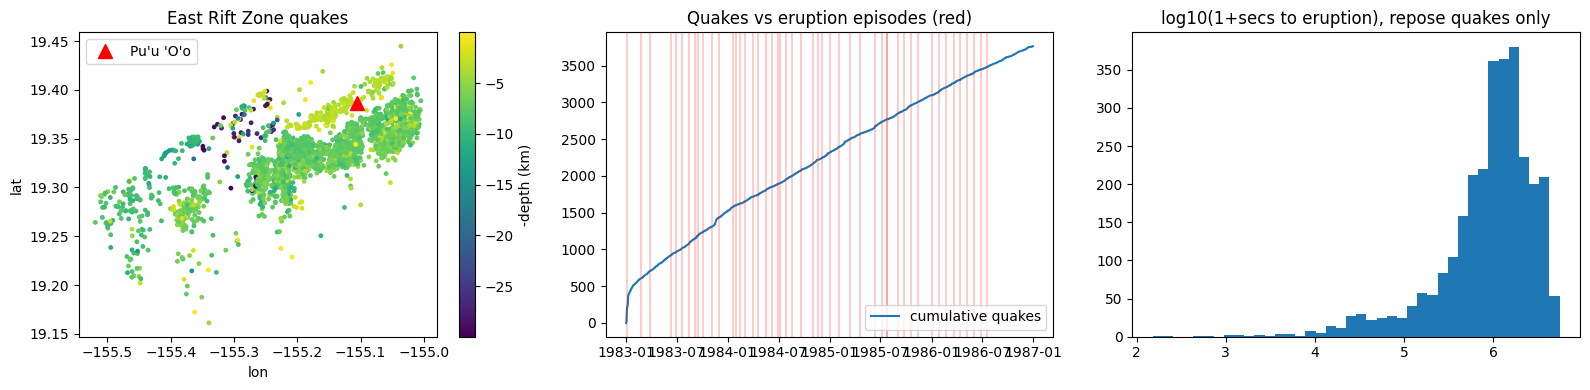

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sc = ax[0].scatter(eq.lon, eq.lat, c=-eq.depth, s=6); plt.colorbar(sc, ax=ax[0], label='-depth (km)')
ax[0].plot(-155.1050, 19.3864, 'r^', ms=10, label="Pu'u 'O'o"); ax[0].legend(); ax[0].set_title('East Rift Zone quakes'); ax[0].set_xlabel('lon'); ax[0].set_ylabel('lat')
ax[1].plot(eq.time, np.cumsum(np.ones(len(eq))), label='cumulative quakes')
for d in er.date: ax[1].axvline(d, color='r', alpha=0.2)
ax[1].set_title('Quakes vs eruption episodes (red)'); ax[1].legend()
ax[2].hist(np.log10(1 + y_tte[y_cls == 0]), bins=40); ax[2].set_title('log10(1+secs to eruption), repose quakes only')
plt.tight_layout(); plt.show()

## 2. Helpers: metrics, models, neural net

In [6]:
RESULTS = []   # collected rows -> final table

def cls_scores(y, yhat, proba=None):
    out = dict(kappa=metrics.cohen_kappa_score(y, yhat),
               auroc=metrics.roc_auc_score(y, yhat),                     # on hard labels (as in the paper)
               auroc_proba=metrics.roc_auc_score(y, proba) if proba is not None else np.nan)
    return out

def log_cls(part, model, split, y, yhat, proba=None):
    s = cls_scores(y, yhat, proba)
    RESULTS.append(dict(part=part, task='classification', model=model, split=split, **s))
    return s

def log_reg(part, model, split, y, yhat):
    RESULTS.append(dict(part=part, task='regression', model=model, split=split,
                        rmse=float(np.sqrt(metrics.mean_squared_error(y, yhat))), r2=metrics.r2_score(y, yhat)))

def best_threshold(y, proba):
    grid = np.linspace(0.05, 0.95, 91)
    ks = [metrics.cohen_kappa_score(y, (proba >= g).astype(int)) for g in grid]
    return grid[int(np.argmax(ks))]

def nearest_centroid(X, C, lab):
    d = ((X[:, None, :] - C[None, :, :]) ** 2).sum(-1)
    return lab[d.argmin(1)]

def elbow(X, kmax=15, title=''):
    ks = np.arange(2, kmax + 1)
    inertia = [KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X).inertia_ for k in ks]
    plt.figure(figsize=(5, 3)); plt.plot(ks, inertia, 'bx-'); plt.xlabel('clusters'); plt.ylabel('inertia'); plt.title(title); plt.show()

In [7]:
# ------------------------- neural net (PyTorch) -------------------------
def make_mlp(n_in, hidden=NN_HIDDEN, depth=4):
    layers, d = [], n_in
    for _ in range(depth):
        layers += [nn.Linear(d, hidden), nn.ReLU()]; d = hidden
    layers.append(nn.Linear(d, 1))
    return nn.Sequential(*layers)

def train_mlp(Xtr, ytr, Xdv, ydv, task, lr, wd, epochs=NN_EPOCHS, batch=NN_BATCH, pos_weight=None, eval_every=10, seed=SEED):
    """4x1000 MLP, SGD, batch 50. Data lives on the GPU (no DataLoader overhead).
    Keeps the checkpoint with the best dev loss (checked every `eval_every` epochs)."""
    torch.manual_seed(seed)
    f32 = dict(dtype=torch.float32, device=device)
    Xt, yt = torch.tensor(Xtr, **f32), torch.tensor(np.asarray(ytr).reshape(-1, 1), **f32)
    Xd, yd = torch.tensor(Xdv, **f32), torch.tensor(np.asarray(ydv).reshape(-1, 1), **f32)
    model = make_mlp(Xt.shape[1]).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=wd)
    if task == 'cls':
        pw = None if pos_weight is None else torch.tensor([pos_weight], **f32)
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pw)
        dev_fn  = nn.BCEWithLogitsLoss(pos_weight=pw)
    else:
        loss_fn, dev_fn = nn.MSELoss(), nn.MSELoss()
    n, hist, best, best_state = len(Xt), [], float('inf'), None
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=device)
        run = torch.zeros((), device=device)
        for i in range(0, n, batch):
            b = perm[i:i + batch]
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(Xt[b]), yt[b])
            loss.backward(); opt.step()
            run += loss.detach() * len(b)
        if ep % eval_every == 0 or ep == epochs - 1:
            model.eval()
            with torch.no_grad():
                dl = dev_fn(model(Xd), yd).item()
            tl = run.item() / n
            hist.append((ep, tl, dl))
            if not np.isfinite(tl):
                print('  loss diverged -> lower the learning rate'); break
            if dl < best:
                best = dl; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            if ep % 100 == 0 or ep == epochs - 1:
                print(f'  epoch {ep:4d}  train {tl:.4f}  dev {dl:.4f}  ({time.time() - t0:.0f}s)')
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, np.array(hist)

def predict_mlp(model, X, task):
    model.eval()
    with torch.no_grad():
        z = model(torch.tensor(X, dtype=torch.float32, device=device)).squeeze(1)
        return (torch.sigmoid(z) if task == 'cls' else z).cpu().numpy()

def plot_hist(hist, title):
    plt.figure(figsize=(5, 3)); plt.plot(hist[:, 0], hist[:, 1], label='train'); plt.plot(hist[:, 0], hist[:, 2], label='dev')
    plt.xlabel('epoch'); plt.ylabel('loss'); plt.title(title); plt.legend(); plt.show()

## 3. Suites that run both tasks on any split / feature set
Each suite takes pre-scaled `X`/`y` for train / dev / test and logs every score into one results table.

In [8]:
def run_classification(part, X, y, tr, dv, te, weighted=False, extra_models=False, tune_threshold=False, do_elbow=False):
    Xtr, Xdv, Xte = X[tr], X[dv], X[te]; ytr, ydv, yte = y[tr], y[dv], y[te]
    sets = {'train': (Xtr, ytr), 'dev': (Xdv, ydv), 'test': (Xte, yte)}
    cw = 'balanced' if weighted else None
    print(f'[{part}] classification  train/dev/test = {len(ytr)}/{len(ydv)}/{len(yte)}   positives: {ytr.mean():.2f}/{ydv.mean():.2f}/{yte.mean():.2f}')

    # --- logistic regression
    lr = LogisticRegression(max_iter=2000, class_weight=cw, random_state=SEED).fit(Xtr, ytr)
    for s, (Xs, ys) in sets.items(): log_cls(part, 'LogReg', s, ys, lr.predict(Xs), lr.predict_proba(Xs)[:, 1])

    # --- k-means per class (8 repose clusters, 2 eruption clusters, as in the paper), nearest centroid
    if do_elbow: elbow(Xtr[ytr == 0], 15, 'k-means elbow: repose quakes')
    k0, k1 = 8, 2
    km0 = KMeans(n_clusters=k0, n_init=10, random_state=SEED).fit(Xtr[ytr == 0])
    km1 = KMeans(n_clusters=k1, n_init=10, random_state=SEED).fit(Xtr[ytr == 1])
    C = np.vstack([km0.cluster_centers_, km1.cluster_centers_]); lab = np.r_[np.zeros(k0), np.ones(k1)]
    for s, (Xs, ys) in sets.items(): log_cls(part, 'KMeans', s, ys, nearest_centroid(Xs, C, lab).astype(int))

    # --- random forest: tune depth on dev AUROC (probabilities), then fit 200 trees
    depths = list(range(1, 33)); tr_auc, dv_auc = [], []
    for d in depths:
        m = RandomForestClassifier(n_estimators=50, max_depth=d, class_weight='balanced_subsample' if weighted else None,
                                   n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
        tr_auc.append(metrics.roc_auc_score(ytr, m.predict_proba(Xtr)[:, 1])); dv_auc.append(metrics.roc_auc_score(ydv, m.predict_proba(Xdv)[:, 1]))
    best_d = depths[int(np.argmax(dv_auc))]
    plt.figure(figsize=(5, 3)); plt.plot(depths, tr_auc, label='train'); plt.plot(depths, dv_auc, label='dev'); plt.axvline(best_d, color='k', ls=':')
    plt.xlabel('max depth'); plt.ylabel('AUROC'); plt.title(f'{part}: RF depth (best={best_d})'); plt.legend(); plt.show()
    rf = RandomForestClassifier(n_estimators=200, max_depth=best_d, class_weight='balanced_subsample' if weighted else None,
                                n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
    thr = best_threshold(ydv, rf.predict_proba(Xdv)[:, 1]) if tune_threshold else 0.5
    for s, (Xs, ys) in sets.items():
        p = rf.predict_proba(Xs)[:, 1]; log_cls(part, 'RandomForest', s, ys, (p >= thr).astype(int), p)
    imp = pd.Series(rf.feature_importances_, index=cols_used).sort_values()
    imp.plot.barh(figsize=(5, 3), title=f'{part}: RF feature importance (classification)'); plt.tight_layout(); plt.show()

    # --- gradient boosting (twist only)
    if extra_models:
        hgb = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.05, max_iter=300, class_weight=cw, random_state=SEED).fit(Xtr, ytr)
        thr = best_threshold(ydv, hgb.predict_proba(Xdv)[:, 1]) if tune_threshold else 0.5
        for s, (Xs, ys) in sets.items():
            p = hgb.predict_proba(Xs)[:, 1]; log_cls(part, 'HistGB', s, ys, (p >= thr).astype(int), p)

    # --- neural net
    if RUN_NN:
        print(f'[{part}] training NN classifier ({NN_EPOCHS} epochs) ...')
        pw = float((ytr == 0).sum() / (ytr == 1).sum()) if weighted else None
        net, hist = train_mlp(Xtr, ytr, Xdv, ydv, 'cls', pos_weight=pw, **NN_CLS)
        plot_hist(hist, f'{part}: NN classifier loss')
        thr = best_threshold(ydv, predict_mlp(net, Xdv, 'cls')) if tune_threshold else 0.5
        for s, (Xs, ys) in sets.items():
            p = predict_mlp(net, Xs, 'cls'); log_cls(part, 'NeuralNet', s, ys, (p >= thr).astype(int), p)

def run_regression(part, X, y, tr, dv, te, extra_models=False, do_elbow=False):
    Xtr, Xdv, Xte = X[tr], X[dv], X[te]; ytr, ydv, yte = y[tr], y[dv], y[te]
    sets = {'train': (Xtr, ytr), 'dev': (Xdv, ydv), 'test': (Xte, yte)}
    print(f'[{part}] time-to-eruption regression')
    preds_test = {}

    # --- k-means on [features, time]; predict = time coordinate of nearest centroid (features only)
    Z = np.column_stack([Xtr, ytr])
    if do_elbow: elbow(Z, 30, 'k-means elbow: features + time-to-eruption')
    km = KMeans(n_clusters=10, n_init=10, random_state=SEED).fit(Z)
    C, Ct = km.cluster_centers_[:, :-1], km.cluster_centers_[:, -1]
    for s, (Xs, ys) in sets.items():
        p = nearest_centroid(Xs, C, Ct); log_reg(part, 'KMeans', s, ys, p)
        if s == 'test': preds_test['KMeans'] = p

    # --- random forest: tune depth on dev R2
    depths = list(range(1, 33)); tr_r2, dv_r2 = [], []
    for d in depths:
        m = RandomForestRegressor(n_estimators=50, max_depth=d, n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
        tr_r2.append(m.score(Xtr, ytr)); dv_r2.append(m.score(Xdv, ydv))
    best_d = depths[int(np.argmax(dv_r2))]
    plt.figure(figsize=(5, 3)); plt.plot(depths, tr_r2, label='train'); plt.plot(depths, dv_r2, label='dev'); plt.axvline(best_d, color='k', ls=':')
    plt.xlabel('max depth'); plt.ylabel('R2'); plt.title(f'{part}: RF regression depth (best={best_d})'); plt.legend(); plt.show()
    rf = RandomForestRegressor(n_estimators=200, max_depth=best_d, n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
    for s, (Xs, ys) in sets.items():
        p = rf.predict(Xs); log_reg(part, 'RandomForest', s, ys, p)
        if s == 'test': preds_test['RandomForest'] = p
    pd.Series(rf.feature_importances_, index=cols_used).sort_values().plot.barh(figsize=(5, 3), title=f'{part}: RF feature importance (regression)')
    plt.tight_layout(); plt.show()

    if extra_models:
        hgb = HistGradientBoostingRegressor(max_depth=6, learning_rate=0.05, max_iter=300, random_state=SEED).fit(Xtr, ytr)
        for s, (Xs, ys) in sets.items():
            p = hgb.predict(Xs); log_reg(part, 'HistGB', s, ys, p)
            if s == 'test': preds_test['HistGB'] = p

    if RUN_NN:
        print(f'[{part}] training NN regressor ({NN_EPOCHS} epochs) ...')
        net, hist = train_mlp(Xtr, ytr, Xdv, ydv, 'reg', **NN_REG)
        plot_hist(hist, f'{part}: NN regressor loss')
        for s, (Xs, ys) in sets.items():
            p = predict_mlp(net, Xs, 'reg'); log_reg(part, 'NeuralNet', s, ys, p)
            if s == 'test': preds_test['NeuralNet'] = p

    # observed vs predicted (test)
    fig, ax = plt.subplots(1, len(preds_test), figsize=(4 * len(preds_test), 3.6), squeeze=False)
    lim = [min(yte.min(), -1), yte.max()]
    for a, (k, p) in zip(ax[0], preds_test.items()):
        a.scatter(p, yte, s=6, c='r'); a.plot(lim, lim, '--'); a.set_title(f'{k}  R2={metrics.r2_score(yte, p):.2f}'); a.set_xlabel('predicted'); a.set_ylabel('observed')
    plt.suptitle(f'{part}: test set, scaled time to eruption'); plt.tight_layout(); plt.show()

## 4. Part A — replication
Authors' index files (`train.txt`, `dev.txt`, `test.txt`: 2633 / 752 / 379 quakes, random split), 7 features, scaler fit on all data (as in the paper).

{'train': 2633, 'dev': 752, 'test': 379}
[A-replication] classification  train/dev/test = 2633/752/379   positives: 0.22/0.22/0.22


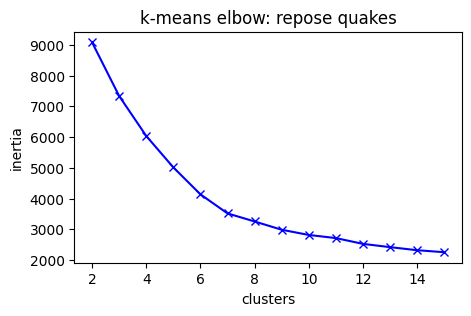

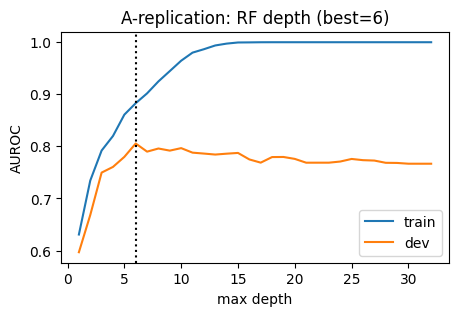

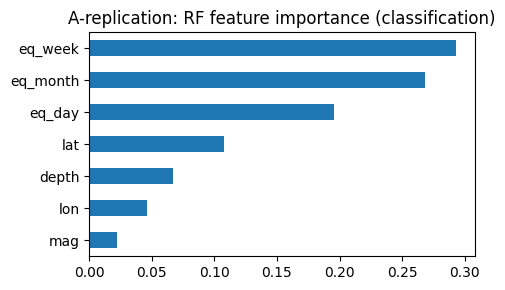

[A-replication] training NN classifier (1000 epochs) ...
  epoch    0  train 0.6533  dev 0.6163  (1s)
  epoch  100  train 0.3873  dev 0.4263  (10s)
  epoch  200  train 0.3628  dev 0.4269  (19s)
  epoch  300  train 0.3430  dev 0.4430  (29s)
  epoch  400  train 0.3155  dev 0.4882  (38s)
  epoch  500  train 0.2864  dev 0.5260  (48s)
  epoch  600  train 0.2697  dev 0.4980  (57s)
  epoch  700  train 0.2266  dev 0.5166  (67s)
  epoch  800  train 0.2107  dev 0.6042  (78s)
  epoch  900  train 0.2043  dev 0.6462  (88s)
  epoch  999  train 0.1506  dev 0.6961  (98s)


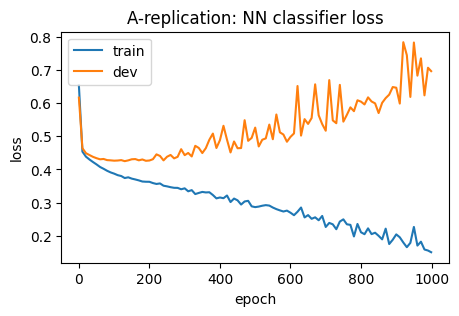

[A-replication] time-to-eruption regression


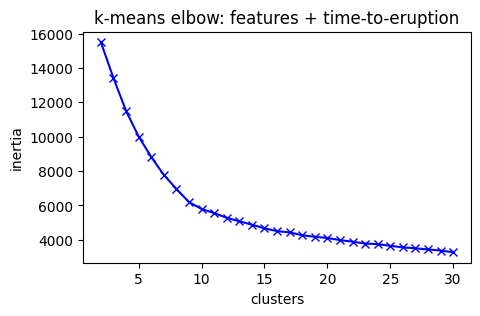

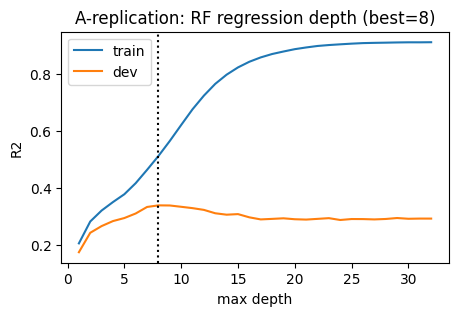

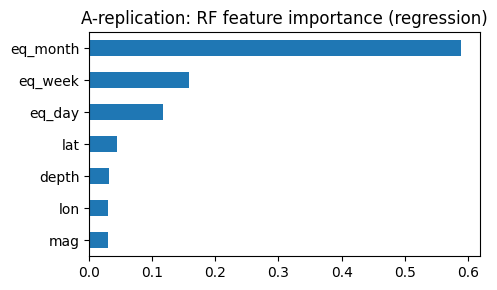

[A-replication] training NN regressor (1000 epochs) ...
  epoch    0  train 0.9405  dev 1.0300  (0s)
  epoch  100  train 0.6267  dev 0.8972  (9s)
  epoch  200  train 0.5464  dev 0.9354  (18s)
  epoch  300  train 0.4350  dev 1.0201  (28s)
  epoch  400  train 0.2997  dev 1.0360  (37s)
  epoch  500  train 0.2120  dev 1.0854  (46s)
  epoch  600  train 0.1419  dev 1.3891  (55s)
  epoch  700  train 0.0845  dev 1.1915  (64s)
  epoch  800  train 0.0622  dev 1.2464  (73s)
  epoch  900  train 0.0514  dev 1.1882  (82s)
  epoch  999  train 0.0297  dev 1.1970  (91s)


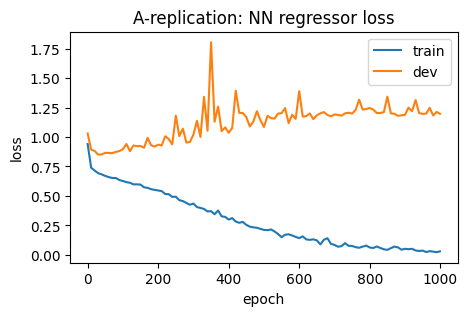

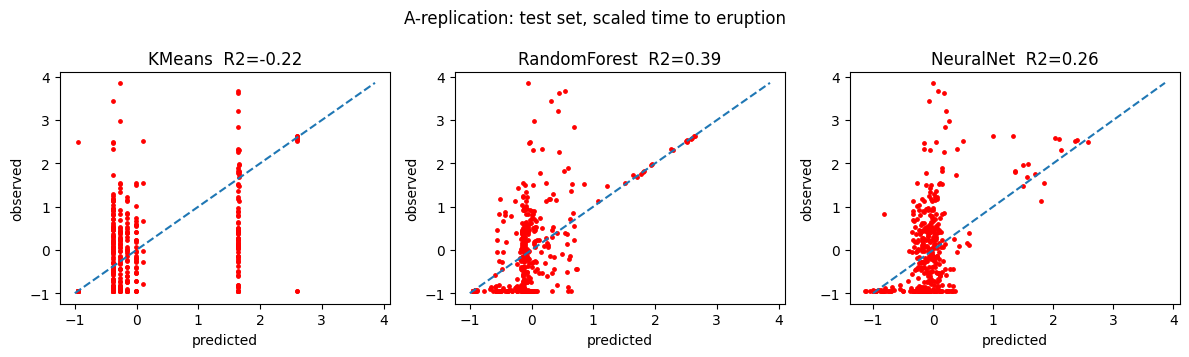

Part A done in 3.9 min


In [9]:
idx = {s: np.loadtxt(f'{s}.txt', dtype=int) for s in ['train', 'dev', 'test']}
assert max(i.max() for i in idx.values()) < len(eq), 'index files do not match the catalogue size'
print({k: len(v) for k, v in idx.items()})

cols_used = BASE_COLS
XA = StandardScaler().fit_transform(feat[cols_used].values)
yA_tte = StandardScaler().fit_transform(y_tte.reshape(-1, 1)).ravel()

t0 = time.time()
run_classification('A-replication', XA, y_cls, idx['train'], idx['dev'], idx['test'], do_elbow=True)
run_regression('A-replication', XA, yA_tte, idx['train'], idx['dev'], idx['test'], do_elbow=True)
print('Part A done in %.1f min' % ((time.time() - t0) / 60))

## 5. Part B — our twist
1. **Blocked-in-time split.** The catalogue is cut into contiguous blocks of `BLOCK_DAYS` days and whole blocks are assigned to train / dev / test (70 / 15 / 15). A random per-quake split (Part A) lets near-simultaneous quakes — which share almost identical rate features and labels — sit on both sides of the split, which inflates scores.
   *(A strictly chronological split isn't possible here: the catalogue ends in 1986 and, from the Kupaianaha episode on 20 Jul 1986, the volcano is labelled erupting for good, so a chronological test set would be all-positive.)*
2. **Scaler fit on training data only.**
3. **Five extra features** (see table at the top).
4. **Imbalance handling:** class-weighted LR / RF / HistGB, weighted BCE for the NN, plus decision threshold chosen on the dev set (maximising Cohen's kappa).
5. **HistGradientBoosting** added as a fifth model family.

{'train': 2848, 'dev': 429, 'test': 487}  positives: {'train': np.float64(0.22), 'dev': np.float64(0.26), 'test': np.float64(0.15)}
[B-twist] classification  train/dev/test = 2848/429/487   positives: 0.22/0.26/0.15


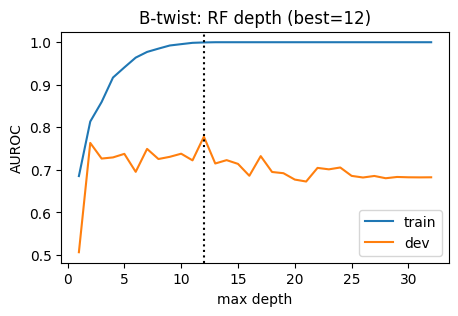

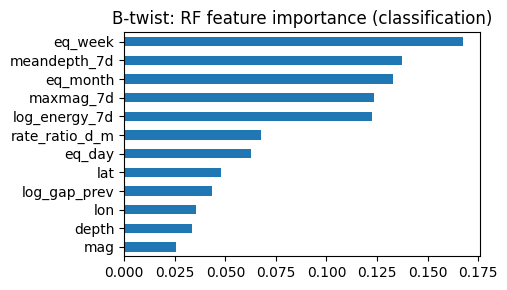

[B-twist] training NN classifier (1000 epochs) ...
  epoch    0  train 1.0606  dev 1.1502  (0s)
  epoch  100  train 0.5582  dev 1.5885  (11s)
  epoch  200  train 0.3129  dev 2.1626  (21s)
  epoch  300  train 0.0761  dev 4.8625  (32s)
  epoch  400  train 0.0245  dev 5.4100  (42s)
  epoch  500  train 0.0134  dev 6.1204  (53s)
  epoch  600  train 0.0296  dev 5.2442  (63s)
  epoch  700  train 0.0097  dev 6.4224  (74s)
  epoch  800  train 0.0196  dev 5.2504  (84s)
  epoch  900  train 0.0100  dev 5.8200  (96s)
  epoch  999  train 0.0086  dev 5.9497  (106s)


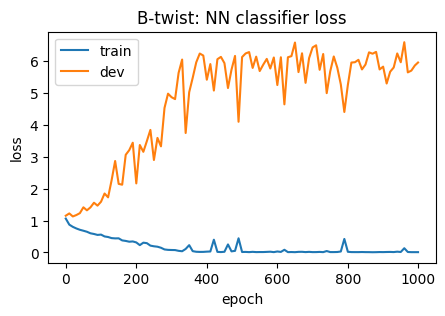

[B-twist] time-to-eruption regression


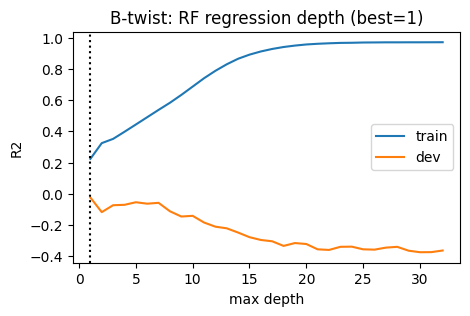

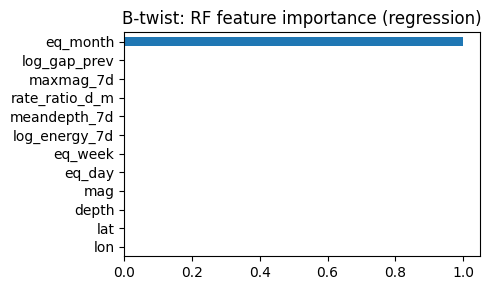

[B-twist] training NN regressor (1000 epochs) ...
  epoch    0  train 0.9696  dev 0.5094  (0s)
  epoch  100  train 0.4618  dev 0.6015  (10s)
  epoch  200  train 0.2031  dev 0.6165  (19s)
  epoch  300  train 0.0958  dev 0.7618  (29s)
  epoch  400  train 0.0282  dev 0.7167  (39s)
  epoch  500  train 0.0098  dev 0.7226  (49s)
  epoch  600  train 0.0079  dev 0.7534  (59s)
  epoch  700  train 0.0021  dev 0.7652  (68s)
  epoch  800  train 0.0007  dev 0.7431  (78s)
  epoch  900  train 0.0010  dev 0.7737  (88s)
  epoch  999  train 0.0002  dev 0.7597  (98s)


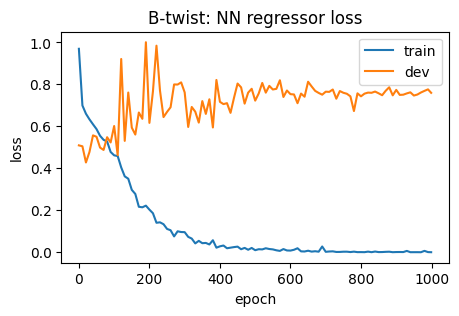

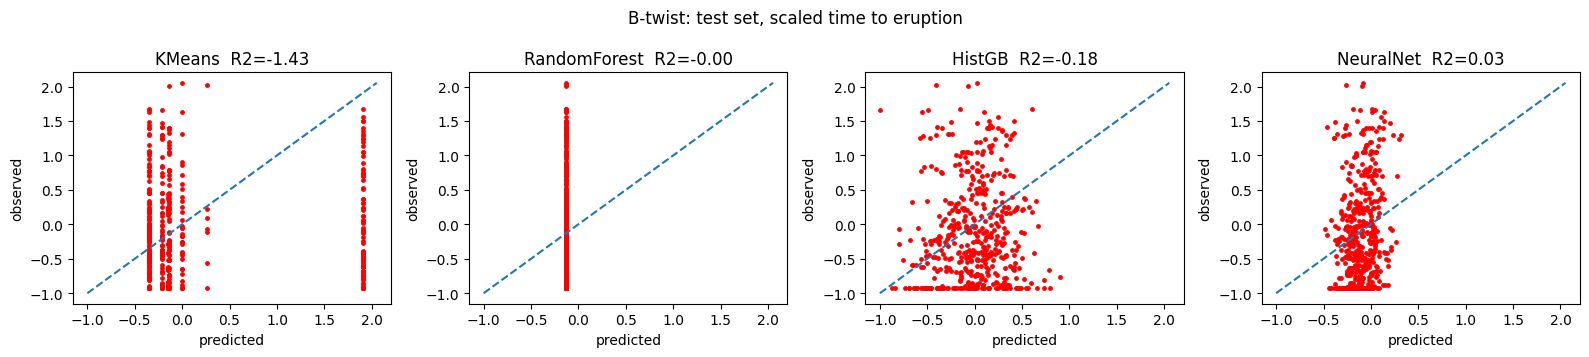

Part B done in 4.3 min


In [10]:
rng = np.random.RandomState(SEED)
block = ((ts - ts[0]) // (BLOCK_DAYS * 86400)).astype(int)
ub = np.unique(block); rng.shuffle(ub)
n_tr, n_dv = int(0.70 * len(ub)), int(0.15 * len(ub))
assign = {b: 'train' for b in ub[:n_tr]}; assign.update({b: 'dev' for b in ub[n_tr:n_tr + n_dv]}); assign.update({b: 'test' for b in ub[n_tr + n_dv:]})
split = np.array([assign[b] for b in block])
idxB = {s: np.where(split == s)[0] for s in ['train', 'dev', 'test']}
print({k: len(v) for k, v in idxB.items()}, ' positives:', {k: round(y_cls[v].mean(), 2) for k, v in idxB.items()})

cols_used = EXT_COLS
scX = StandardScaler().fit(feat.loc[idxB['train'], cols_used].values)
XB = scX.transform(feat[cols_used].values)
scY = StandardScaler().fit(y_tte[idxB['train']].reshape(-1, 1))
yB_tte = scY.transform(y_tte.reshape(-1, 1)).ravel()

t0 = time.time()
run_classification('B-twist', XB, y_cls, idxB['train'], idxB['dev'], idxB['test'], weighted=True, extra_models=True, tune_threshold=True)
run_regression('B-twist', XB, yB_tte, idxB['train'], idxB['dev'], idxB['test'], extra_models=True)
print('Part B done in %.1f min' % ((time.time() - t0) / 60))

## 6. Results

In [11]:
res = pd.DataFrame(RESULTS)
pd.set_option('display.width', 200)

print('=== Classification: test set ===')
c = res[(res.task == 'classification') & (res.split == 'test')][['part', 'model', 'kappa', 'auroc', 'auroc_proba']].round(3)
display(c.sort_values(['part', 'kappa'], ascending=[True, False]).reset_index(drop=True))

print('=== Regression: test set (scaled time to eruption) ===')
r = res[(res.task == 'regression') & (res.split == 'test')][['part', 'model', 'rmse', 'r2']].round(3)
display(r.sort_values(['part', 'r2'], ascending=[True, False]).reset_index(drop=True))

res.to_csv('all_results.csv', index=False)
print('full table (train/dev/test) saved to all_results.csv')

=== Classification: test set ===


,part,model,kappa,auroc,auroc_proba
0,A-replication,NeuralNet,0.394,0.652,0.730
1,A-replication,RandomForest,0.393,0.646,0.801
2,A-replication,LogReg,0.335,0.631,0.695
3,A-replication,KMeans,0.185,0.590,NaN
4,B-twist,RandomForest,0.104,0.581,0.578
5,B-twist,LogReg,0.098,0.554,0.575
6,B-twist,HistGB,0.094,0.567,0.586
7,B-twist,KMeans,-0.058,0.461,NaN
8,B-twist,NeuralNet,-0.123,0.394,0.344


=== Regression: test set (scaled time to eruption) ===


,part,model,rmse,r2
0,A-replication,RandomForest,0.797,0.390
1,A-replication,NeuralNet,0.880,0.256
2,A-replication,KMeans,1.125,-0.216
3,B-twist,NeuralNet,0.708,0.034
4,B-twist,RandomForest,0.720,-0.000
5,B-twist,HistGB,0.782,-0.180
6,B-twist,KMeans,1.122,-1.427


full table (train/dev/test) saved to all_results.csv


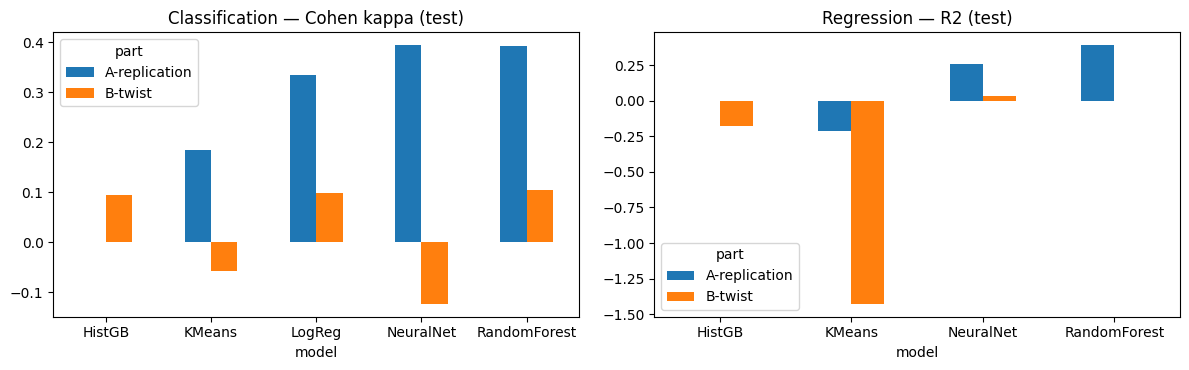

In [12]:
# side-by-side bar charts (test split)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
c.pivot(index='model', columns='part', values='kappa').plot.bar(ax=ax[0], rot=0, title='Classification — Cohen kappa (test)')
r.pivot(index='model', columns='part', values='r2').plot.bar(ax=ax[1], rot=0, title='Regression — R2 (test)')
plt.tight_layout(); plt.savefig('summary_test_scores.png', dpi=200); plt.show()

### How to write this up
* **Compare against the paper** (Fig. 4/5): RF kappa ≈ 0.42–0.52, AUROC ≈ 0.71; time-to-eruption R² ≈ 0.38 for RF, other models weaker. Your Part A numbers will differ slightly (different library versions, float32 NN, shuffled batches, 1000 epochs, RF depth tuned on probabilities, 200 trees).
* **Part A → Part B drop** (if any) is the effect of removing split leakage — a result in itself.
* Discuss which extra features helped (RF importance plots) and whether class weighting / threshold tuning changed the confusion pattern.
* Limitations: catalogue ends in 1986; "erupting" labels come from a coarse episode table with a 24 h buffer; single volcano; time-to-eruption in a periodic fountaining phase is largely determined by the cycle, not by individual quakes.
* Stochasticity: re-run with different `SEED` values (top cell) and report mean ± std if your instructor wants error bars.